# Xiao_Hongwei_HW3

Name: Hongwei Xiao  
GitHub username: Ga9a  
Course: DSCI 552

## 1. Time series classification, Part 1: Feature creation/extraction

### (a) Load the AReM data

I use the data provided with the homework, saved in `../data/AReM/`. There are 88 CSV files in seven activity folders. Each file is one instance with six time series. I leave out the time column when calculating the features.

Source: [UCI AReM dataset](https://archive.ics.uci.edu/dataset/366/activity+recognition+system+based+on+multisensor+data+fusion+arem).

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Support running from either the repository root or the notebooks folder.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data' / 'AReM').is_dir() else Path.cwd().parent
DATA_DIR = PROJECT_ROOT / 'data' / 'AReM'
RESULTS_DIR = PROJECT_ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
assert DATA_DIR.is_dir(), 'Open this notebook from HW3 or HW3/notebooks.'

SEED = 42
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
ACTIVITIES = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
sns.set_theme(style='whitegrid')
pd.set_option('display.precision', 4)

In [2]:
def read_instance(path):
    """Read both comma- and whitespace-delimited source files without dropping records."""
    rows = []
    for line_number, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        # A few source files have whitespace separators or a trailing comma.
        values = re.split(r'[,\s]+', line.rstrip(',').strip())
        if len(values) != 7:
            raise ValueError(f'{path.name}, line {line_number}: expected 7 values')
        rows.append([float(value) for value in values])
    frame = pd.DataFrame(rows, columns=['time'] + SERIES)
    assert np.isfinite(frame.to_numpy()).all(), f'Non-finite values: {path}'
    assert frame['time'].is_unique and frame['time'].is_monotonic_increasing
    return frame

instances = {}
records = []
for activity in ACTIVITIES:
    files = sorted((DATA_DIR / activity).glob('dataset*.csv'),
                   key=lambda path: int(path.stem.replace('dataset', '')))
    for path in files:
        instance_id = len(records) + 1
        frame = read_instance(path)
        instances[instance_id] = frame
        records.append({
            'instance': instance_id,
            'activity': activity,
            'dataset': int(path.stem.replace('dataset', '')),
            'file': path.relative_to(DATA_DIR).as_posix(),
            'n_observations': len(frame),
        })

metadata = pd.DataFrame(records).set_index('instance')
assert len(instances) == 88
display(metadata.groupby('activity', sort=False).agg(
    instances=('file', 'size'), min_length=('n_observations', 'min'),
    max_length=('n_observations', 'max')))
print('Files with a length different from 480:')
display(metadata.loc[metadata['n_observations'] != 480])

,instances,min_length,max_length
activity,,,
bending1,7,480,480
bending2,6,480,480
cycling,15,480,480
lying,15,480,480
sitting,15,479,480
standing,15,480,480
walking,15,480,480


Files with a length different from 480:


,activity,dataset,file,n_observations
instance,,,,
51,sitting,8,sitting/dataset8.csv,479


There are two issues with the files. `bending2/dataset4.csv` uses spaces instead of commas, so the reading function accepts both. It also skips the five header lines and handles commas at the end of a row.

`sitting/dataset8.csv` has 479 data rows, while the other 87 files have 480. I use the 479 available rows without filling in the missing row. This keeps all 88 instances. The same issue is mentioned in [Piazza post 89](https://piazza.com/class/mt7h6ldc1j86hm/post/89); the student reply suggests explaining how it was handled.

### (b) Separate training and test instances

Following the question, I put datasets 1 and 2 from `bending1` and `bending2` in the test set. For the other activities, I use datasets 1, 2, and 3 as test data. All remaining files go into the training set. Each file stays together in one set.

In [3]:
test_limit = metadata['activity'].map(lambda name: 2 if name in ['bending1', 'bending2'] else 3)
metadata['split'] = np.where(metadata['dataset'] <= test_limit, 'test', 'train')
train_ids = metadata.index[metadata['split'] == 'train']
test_ids = metadata.index[metadata['split'] == 'test']
train_instances = {i: instances[i] for i in train_ids}
test_instances = {i: instances[i] for i in test_ids}

assert len(train_ids) == 69 and len(test_ids) == 19
assert set(train_ids).isdisjoint(test_ids)
assert set(train_ids) | set(test_ids) == set(instances)
split_counts = pd.crosstab(metadata['activity'], metadata['split']).reindex(ACTIVITIES)
split_counts['total'] = split_counts.sum(axis=1)
display(split_counts)
print(f'Training instances: {len(train_ids)}; test instances: {len(test_ids)}')
metadata.to_csv(RESULTS_DIR / 'instance_manifest.csv')

split,test,train,total
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15


Training instances: 69; test instances: 19


This gives 69 training instances and 19 test instances. I extract features for all 88 files below, as shown in the question, and keep the split for HW4. I do not standardize the combined data or fit a model here.

### (c) Feature extraction

#### (i) Common time-domain features

Common features include mean, median, minimum, maximum, and quartiles. Variance, standard deviation, range, and interquartile range describe how spread out the values are. Other examples are skewness, kurtosis, root mean square, and energy (the sum of squared values).

Some features also describe changes over time, such as the average absolute change between consecutive values, trend, number of peaks, threshold crossings, and autocorrelation.

I referred to the [tsfresh feature list](https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html). Here I use the seven features required by the question. These seven do not keep the order of the observations, so rearranging a series would give the same results.

#### (ii) Extract 42 features per instance

I use the values directly without normalization. For standard deviation, I use `ddof=1`. The quartiles use linear interpolation. The numbers 1 to 6 in the column names refer to the six series in the order listed above. For example, `q1_6` is the first quartile of `var_rss23`.

In [4]:
STATISTICS = ['min', 'max', 'mean', 'median', 'std', 'q1', 'q3']

def extract_features(frame):
    result = {}
    for j, column in enumerate(SERIES, start=1):
        values = frame[column]
        statistics = [values.min(), values.max(), values.mean(), values.median(),
                      values.std(ddof=1), values.quantile(0.25), values.quantile(0.75)]
        for statistic, value in zip(STATISTICS, statistics):
            result[f'{statistic}_{j}'] = value
    return result

features = pd.DataFrame.from_dict(
    {i: extract_features(frame) for i, frame in instances.items()}, orient='index')
features.index.name = 'instance'
X_train = features.loc[train_ids].copy()
X_test = features.loc[test_ids].copy()
assert features.shape == (88, 42)
assert np.isfinite(features.to_numpy()).all()

print(f'All features: {features.shape}; train: {X_train.shape}; test: {X_test.shape}')
with pd.option_context('display.max_rows', 88, 'display.max_columns', 42):
    display(features)

features.to_csv(RESULTS_DIR / 'features_all.csv')
metadata[['activity', 'dataset', 'split']].join(features).to_csv(
    RESULTS_DIR / 'features_with_labels.csv')
metadata.loc[train_ids, ['activity', 'dataset']].join(X_train).to_csv(
    RESULTS_DIR / 'features_train.csv')
metadata.loc[test_ids, ['activity', 'dataset']].join(X_test).to_csv(
    RESULTS_DIR / 'features_test.csv')

All features: (88, 42); train: (69, 42); test: (19, 42)


,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,median_2,std_2,q1_2,q3_2,min_3,max_3,mean_3,median_3,std_3,q1_3,q3_3,min_4,max_4,mean_4,median_4,std_4,q1_4,q3_4,min_5,max_5,mean_5,median_5,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.6248,40.500,1.4770,39.2500,42.0000,0.0,1.30,0.3586,0.430,0.3226,0.0000,0.5000,4.00,29.50,19.0409,19.250,4.4630,16.0000,23.2500,0.0,7.23,0.8325,0.500,0.9657,0.0000,1.1200,27.25,38.25,34.3113,35.000,2.1884,33.0000,36.0000,0.00,1.92,0.5706,0.430,0.5829,0.0000,1.3000
2,38.00,45.67,42.8128,42.500,1.4355,42.0000,43.6700,0.0,1.22,0.3724,0.470,0.2892,0.0000,0.5000,2.00,29.50,20.0970,21.000,3.8937,19.0000,22.2500,0.0,5.76,0.8764,0.500,1.0473,0.0000,1.1450,27.67,38.50,33.0246,33.000,1.9953,32.0000,34.5000,0.00,3.11,0.5711,0.430,0.6010,0.0000,1.3000
3,35.00,47.40,43.9545,44.330,1.5588,43.0000,45.0000,0.0,1.70,0.4263,0.470,0.3387,0.0000,0.5000,6.50,29.75,22.1224,23.000,3.0309,19.7500,24.0000,0.0,4.44,0.4973,0.430,0.5507,0.0000,0.8300,29.00,38.50,35.5885,36.000,1.9996,35.3625,36.5000,0.00,1.79,0.4933,0.430,0.5135,0.0000,0.9400
4,33.00,47.75,42.1798,43.500,3.6707,39.1500,45.0000,0.0,3.00,0.6960,0.500,0.6309,0.0000,1.1200,8.50,30.00,22.1836,23.000,3.8105,20.5000,24.3725,0.0,5.15,0.9899,0.830,0.9537,0.4300,1.3000,20.00,38.67,33.4939,35.000,3.8494,30.4575,36.3300,0.00,2.18,0.6135,0.500,0.5243,0.0000,1.0000
5,33.00,45.75,41.6781,41.750,2.2435,41.3300,42.7500,0.0,2.83,0.5360,0.500,0.4055,0.4300,0.7100,3.00,28.25,19.0066,19.125,4.0871,16.5000,22.0625,0.0,6.42,0.8419,0.500,0.9288,0.4300,1.1200,23.67,37.50,29.8571,30.000,2.4110,28.4575,31.2500,0.00,1.79,0.3833,0.430,0.3892,0.0000,0.5000
6,37.00,48.00,43.4550,43.250,1.3861,42.5000,45.0000,0.0,1.58,0.3781,0.470,0.3156,0.0000,0.5000,5.75,27.00,15.7933,15.000,3.8476,13.0000,18.2700,0.0,10.03,0.8494,0.500,0.9958,0.4300,1.1200,8.00,33.50,23.0348,23.500,2.4889,22.2500,24.0000,0.00,5.26,0.6796,0.500,0.6225,0.4300,0.8700
7,36.25,48.00,43.9691,44.500,1.6184,43.3100,44.6700,0.0,1.50,0.4131,0.470,0.2631,0.4300,0.5000,1.50,26.33,15.8680,16.250,3.7424,14.2500,18.0000,0.0,5.17,0.6664,0.470,0.7890,0.0000,0.9400,11.33,30.75,22.1038,21.670,3.3183,20.5000,23.7500,0.00,2.96,0.5553,0.490,0.4878,0.0000,0.8300
8,12.75,51.00,24.5630,24.250,3.7375,23.1875,26.5000,0.0,6.87,0.5908,0.430,0.8374,0.0000,0.7100,0.00,25.33,19.1213,20.250,4.2996,18.0000,22.0000,0.0,6.76,0.7368,0.470,0.9270,0.0000,0.8700,10.67,30.00,23.4930,23.750,3.6938,20.5000,27.0000,0.00,4.97,0.7002,0.500,0.6937,0.4300,0.8700
9,0.00,42.75,27.4646,28.000,3.5836,25.5000,30.0000,0.0,7.76,0.4497,0.430,0.7672,0.0000,0.5000,7.50,35.00,20.8425,20.750,3.8263,18.0000,22.5000,0.0,5.76,0.7799,0.500,0.9044,0.0000,0.9400,0.00,33.00,17.6179,18.000,5.0536,15.0000,20.7500,0.00,6.76,1.1221,0.830,1.0123,0.4700,1.3000


The result has 88 rows and 42 feature columns: seven features for each of the six series. I save the full table in `results/features_all.csv`. The activity labels and file information are separate from the features, and the saved train and test tables follow part (b).

#### (iii) Standard deviations and 90% bootstrap confidence intervals

Here I calculate the standard deviation of each feature column across the 88 instances. For example, `std_1` is calculated within each file first. Taking the standard deviation of that column tells us how much those values differ between files.

For the bootstrap, I randomly sample 88 rows with replacement and calculate the standard deviations again. I repeat this 10,000 times, using `ddof=1` and seed 42. The 5th and 95th percentiles give the 90% confidence interval for each feature's standard deviation. I sample whole rows so the features from one instance stay together.

Each interval is calculated separately. The method treats the instances as independent samples and does not account for possible dependence between recordings from the same person or session.

In [5]:
N_BOOTSTRAP = 10_000
BATCH_SIZE = 250
rng = np.random.default_rng(SEED)
values = features.to_numpy(dtype=float)
n_instances, n_features = values.shape
bootstrap_std = np.empty((N_BOOTSTRAP, n_features))

for start in range(0, N_BOOTSTRAP, BATCH_SIZE):
    stop = min(start + BATCH_SIZE, N_BOOTSTRAP)
    sample_indices = rng.integers(0, n_instances, size=(stop - start, n_instances))
    bootstrap_std[start:stop] = values[sample_indices].std(axis=1, ddof=1)

lower, upper = np.quantile(bootstrap_std, [0.05, 0.95], axis=0)
std_intervals = pd.DataFrame({
    'sample_std': features.std(axis=0, ddof=1),
    'ci_90_lower': lower,
    'ci_90_upper': upper,
})
std_intervals.index.name = 'feature'
assert len(std_intervals) == 42
assert (std_intervals['ci_90_lower'] <= std_intervals['ci_90_upper']).all()
assert (std_intervals.to_numpy() >= 0).all()
with pd.option_context('display.max_rows', 42):
    display(std_intervals)
std_intervals.to_csv(RESULTS_DIR / 'feature_std_90ci.csv')

,sample_std,ci_90_lower,ci_90_upper
feature,,,
min_1,9.5700,8.2360,10.7739
max_1,4.3944,3.3399,5.2931
mean_1,5.3357,4.7038,5.8758
median_1,5.4401,4.7840,6.0063
std_1,1.7722,1.5694,1.9495
q1_1,6.1536,5.5738,6.6486
q3_1,5.1389,4.3386,5.8340
min_2,0.0000,0.0000,0.0000
max_2,5.0627,4.6306,5.4011


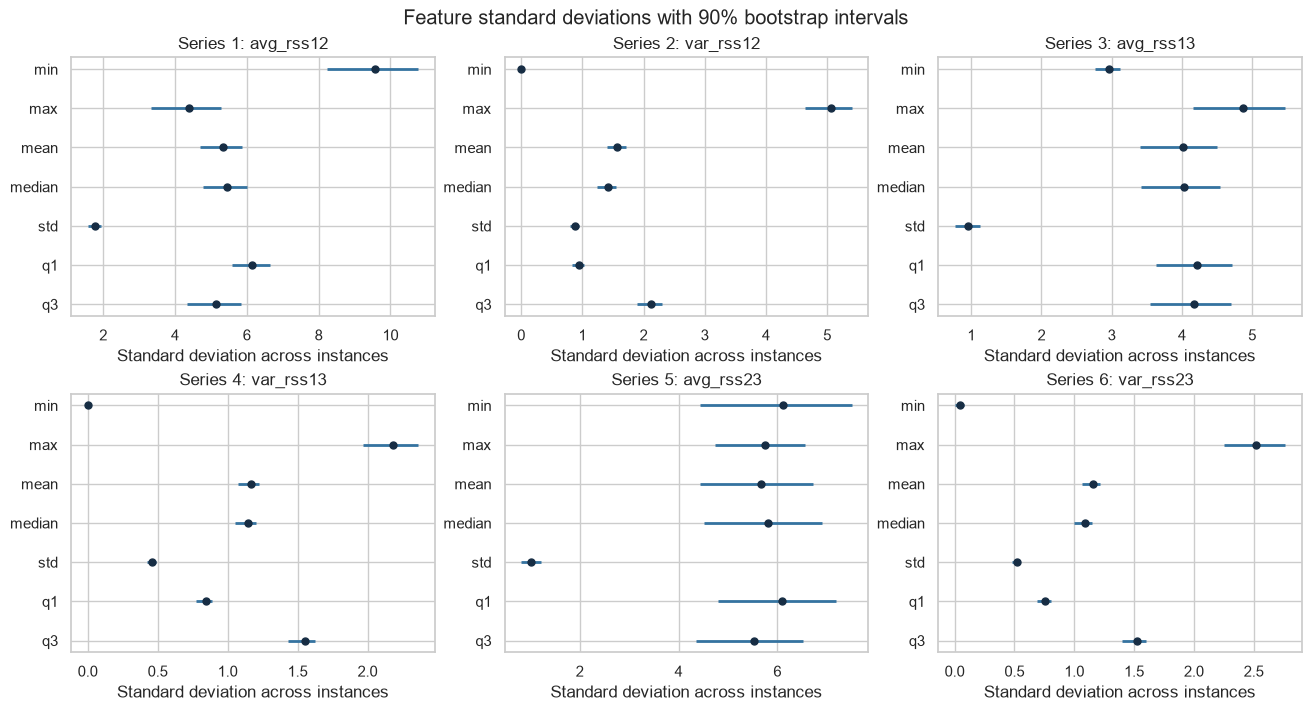

mean_1: SD = 5.3357, 90% CI = [4.7038, 5.8758]
std_2: SD = 0.8841, 90% CI = [0.8015, 0.9425]
min_2: SD = 0.0000, 90% CI = [0.0000, 0.0000]


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for j, ax in enumerate(axes.flat, start=1):
    rows = std_intervals.loc[[f'{name}_{j}' for name in STATISTICS]]
    positions = np.arange(len(STATISTICS))
    ax.hlines(positions, rows['ci_90_lower'], rows['ci_90_upper'], color='#3573a0', linewidth=2)
    ax.scatter(rows['sample_std'], positions, color='#172d44', s=25, zorder=3)
    ax.set_yticks(positions, STATISTICS)
    ax.invert_yaxis()
    ax.set_title(f'Series {j}: {SERIES[j-1]}')
    ax.set_xlabel('Standard deviation across instances')
fig.suptitle('Feature standard deviations with 90% bootstrap intervals')
fig.savefig(RESULTS_DIR / 'feature_std_90ci.png', dpi=160, bbox_inches='tight')
plt.show()

for name in ['mean_1', 'std_2', 'min_2']:
    row = std_intervals.loc[name]
    print(f"{name}: SD = {row['sample_std']:.4f}, "
          f"90% CI = [{row['ci_90_lower']:.4f}, {row['ci_90_upper']:.4f}]")

For `mean_1`, the standard deviation is 5.3357 and the 90% interval is [4.7038, 5.8758]. For `std_2`, they are 0.8841 and [0.8015, 0.9425]. The intervals show the uncertainty in these estimates.

`min_2` and `min_4` are zero for every instance, so their standard deviations and intervals are also zero. These two columns would not help separate the activities in this dataset. This does not mean they must be zero in every possible recording. Also, a feature with a large standard deviation is not necessarily useful: it could vary a lot even within the same activity.

#### (iv) Select three time-domain feature types

I would choose mean, standard deviation, and maximum. The mean gives the average level, and the standard deviation shows how much the values change. I also keep the maximum because a short peak may not affect the mean very much. Using these three for all six series gives 18 features.

The maximum can be affected by an outlier. These are reasonable choices to start with, but I would compare them with other features using cross-validation on the training data in HW4. The table and plots below use only the training set.

,mean_1,std_2,max_6
activity,,,
bending1,43.0473,0.3907,2.7960
bending2,31.1161,0.5917,7.9150
cycling,36.6175,1.9296,9.1767
lying,39.8208,0.2921,4.1417
sitting,41.0591,0.3786,5.8308
standing,43.9663,0.3657,5.2692
walking,34.5089,2.4581,9.1008


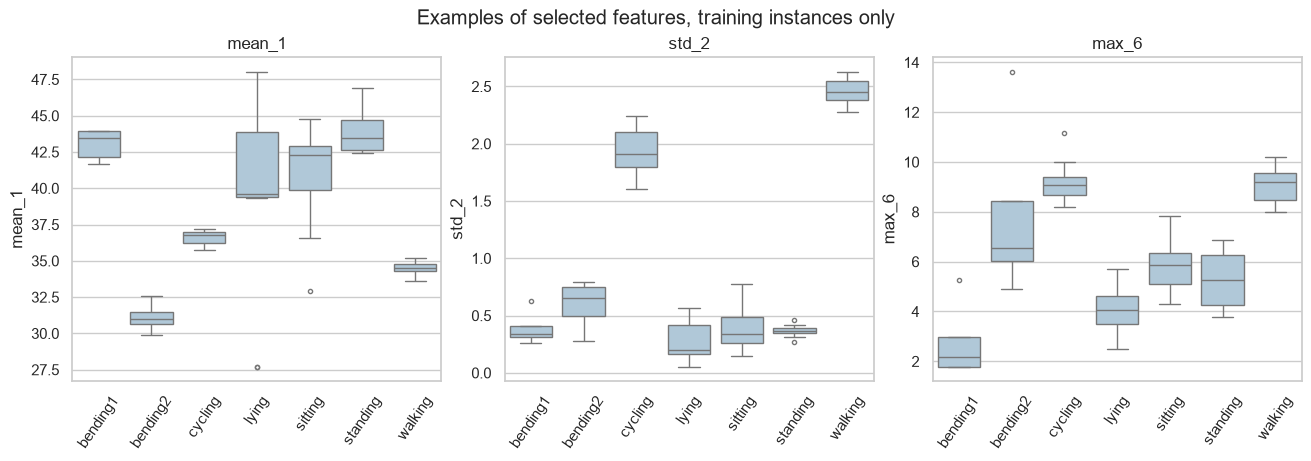

In [7]:
selected_types = ['mean', 'std', 'max']
selected_columns = [f'{statistic}_{j}' for j in range(1, 7) for statistic in selected_types]
X_train_selected = X_train[selected_columns]
X_test_selected = X_test[selected_columns]
assert X_train_selected.shape == (69, 18)
assert X_test_selected.shape == (19, 18)

training_summary = metadata.loc[train_ids, ['activity']].join(X_train_selected)
example_columns = ['mean_1', 'std_2', 'max_6']
activity_means = training_summary.groupby('activity')[example_columns].mean().reindex(ACTIVITIES)
display(activity_means)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), constrained_layout=True)
for ax, column in zip(axes, example_columns):
    sns.boxplot(data=training_summary, x='activity', y=column, order=ACTIVITIES,
                color='#a9c9df', ax=ax, fliersize=3)
    ax.tick_params(axis='x', rotation=55)
    ax.set_xlabel('')
    ax.set_title(column)
fig.suptitle('Examples of selected features, training instances only')
fig.savefig(RESULTS_DIR / 'selected_features_train.png', dpi=160, bbox_inches='tight')
plt.show()

For example, the average `mean_1` is 31.1161 for bending2 and 43.9663 for standing. Walking and cycling have average `std_2` values of 2.4581 and 1.9296, much higher than lying at 0.2921. The average `max_6` is 2.7960 for bending1 and 9.1008 for walking. These differences give some support for the choices above.

There is still overlap. Cycling and walking have similar `max_6` values, and standing and bending1 overlap in `mean_1`. So one feature alone is not enough to separate all the activities. These plots do not tell us the test accuracy or prove that this is the best feature set.

## 2. ISLR 3.7.4

Both models are fitted to the same 100 observations using least squares. Both include an intercept; the cubic model also includes $X^2$ and $X^3$.

### (a) Linear relationship: training RSS

The cubic model will have lower or equal training RSS. It can give the same fit as the linear model by setting the coefficients of $X^2$ and $X^3$ to zero. Adding these terms cannot make the best training fit worse, and they may fit some of the noise even when the true relationship is linear.

### (b) Linear relationship: test RSS

I would expect the linear model to have lower test RSS. Since the true relationship is linear, the extra terms are unnecessary and can fit noise in the training data. This increases variance and can make predictions worse. However, the linear model is not guaranteed to win on every test set.

### (c) Nonlinear relationship: training RSS

The cubic model still has lower or equal training RSS. The reason is the same as in part (a): the linear fit is one of the fits allowed by the cubic model. This holds even if the true relationship is nonlinear.

### (d) Nonlinear relationship: test RSS

There is not enough information to tell. If the relationship has a clear curve that a cubic model fits well, the cubic model may have lower test RSS. If it is close to linear, the simpler model may do better because it has less variance. A nonlinear relationship also does not have to follow a cubic shape, so we would need more information about the relationship and noise, or validation results.

Reference: [ISLR, first edition, Chapter 3, Exercise 4, pp. 120-121](https://www.statlearning.com/s/ISLRSeventhPrinting.pdf), by James, Witten, Hastie, and Tibshirani.

## References and AI assistance

The data source, tsfresh documentation, and ISLR are linked in the relevant answers above.

I used AI for function-usage questions and example code, and for help writing the data-loading, feature-extraction, and bootstrap code and explanations. The notebook was run to check the results.

The optional practice questions and the HW4 classification section are not included.